# 5장. 머신러닝을 이용한 불량 위험 예측

같은 데이터 분리와 같은 지표로 모델 4종(+기준선)을 비교합니다.
- 개발 데이터(앞 80%): 시간 교차검증으로 모델·설정 선택
- 평가 데이터(뒤 20%): 모든 선택을 마친 뒤 마지막에 한 번만 사용

In [1]:
import os
import sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("src").exists():
    !git clone -q https://github.com/ady95/manufacturing-ai-tutorial.git
    %cd manufacturing-ai-tutorial/01-yield-risk
    !pip install -q optuna

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
Path("results").mkdir(exist_ok=True)

In [2]:
import json
import platform
import time
import warnings

import lightgbm
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import sklearn
import xgboost
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

from src.secom_utils import (
    SEED, bootstrap_ci, dev_test_split, evaluate, load_secom, make_models,
    make_preprocessor, oof_predict, time_folds, timed_fit_predict,
)

warnings.filterwarnings("ignore", category=UserWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)
ENV = {"python": platform.python_version(), "sklearn": sklearn.__version__,
       "xgboost": xgboost.__version__, "lightgbm": lightgbm.__version__, "optuna": optuna.__version__}
print(ENV)

{'python': '3.12.9', 'sklearn': '1.9.1', 'xgboost': '3.4.1', 'lightgbm': '4.7.0', 'optuna': '5.1.0'}


In [3]:
X, y, ts = load_secom()
(X_dev, y_dev, ts_dev), (X_test, y_test, ts_test) = dev_test_split(X, y, ts, test_size=0.2)
FOLDS = time_folds(len(y_dev), start=0.4, k=3)
for i, (tr, te) in enumerate(FOLDS, 1):
    print(f"fold {i}: 학습 {len(tr):4d}건 → 예측 {len(te)}건 (불량 {int(y_dev.iloc[te].sum())}건)")
RANDOM_CV = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X_dev, y_dev))


def score_dev(make_model):
    """개발 데이터에서 (시간 교차검증 OOF PR-AUC, 무작위 교차검증 평균 PR-AUC)."""
    _, yt, pt, _ = oof_predict(make_model, X_dev, y_dev, FOLDS)
    _, _, _, rand_ap = oof_predict(make_model, X_dev, y_dev, RANDOM_CV)
    return average_precision_score(yt, pt), float(np.mean(rand_ap))

fold 1: 학습  501건 → 예측 250건 (불량 8건)
fold 2: 학습  751건 → 예측 251건 (불량 9건)
fold 3: 학습 1002건 → 예측 251건 (불량 11건)


## 5-1. Logistic Regression 기준 모델

In [4]:
def make_lr(pos_weight=None, k="all", C=0.01):
    steps = [("prep", make_preprocessor(scale=True))]
    if k != "all":
        steps.append(("select", SelectKBest(f_classif, k=k)))
    steps.append(("clf", LogisticRegression(C=C, class_weight="balanced", max_iter=5000)))
    return Pipeline(steps)


lr_time, lr_rand = score_dev(lambda pw: make_lr())
print(f"LR(전체 특성) 시간CV PR-AUC {lr_time:.3f} | 무작위CV PR-AUC {lr_rand:.3f}")

LR(전체 특성) 시간CV PR-AUC 0.064 | 무작위CV PR-AUC 0.154


In [5]:
# 특성 선택 개수(k)와 규제 강도(C)를 개발 데이터의 시간 교차검증으로만 고릅니다.
grid = []
for k in [10, 20, 40, 80, "all"]:
    for C in [0.01, 0.1, 1.0]:
        _, yt, pt, _ = oof_predict(lambda pw, k=k, C=C: make_lr(k=k, C=C), X_dev, y_dev, FOLDS)
        grid.append({"k": str(k), "C": C, "time_cv_ap": average_precision_score(yt, pt)})
grid = pd.DataFrame(grid).sort_values("time_cv_ap", ascending=False).reset_index(drop=True)
print(grid.round(3).head(6).to_string())
best_k = grid.loc[0, "k"]
best_k = best_k if best_k == "all" else int(best_k)
best_C = float(grid.loc[0, "C"])
print("선택:", best_k, best_C)

    k     C  time_cv_ap
0  80  0.10       0.127
1  40  1.00       0.116
2  80  0.01       0.109
3  80  1.00       0.108
4  40  0.10       0.104
5  10  1.00       0.079
선택: 80 0.1


## 5-2 ~ 5-3. Random Forest, XGBoost, LightGBM

In [6]:
def make_xgb(pos_weight, **params):
    base = dict(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.5)
    base.update(params)
    return Pipeline([
        ("prep", make_preprocessor(scale=False)),
        ("clf", XGBClassifier(**base, scale_pos_weight=pos_weight, eval_metric="aucpr",
                              n_jobs=-1, random_state=SEED)),
    ])


def objective(trial):
    params = dict(
        n_estimators=trial.suggest_int("n_estimators", 100, 600, step=50),
        max_depth=trial.suggest_int("max_depth", 2, 6),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        subsample=trial.suggest_float("subsample", 0.5, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.2, 0.8),
        min_child_weight=trial.suggest_float("min_child_weight", 1, 20, log=True),
        reg_lambda=trial.suggest_float("reg_lambda", 0.1, 50, log=True),
    )
    _, yt, pt, _ = oof_predict(lambda pw: make_xgb(pw, **params), X_dev, y_dev, FOLDS)
    return average_precision_score(yt, pt)


t0 = time.perf_counter()
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=40)
optuna_sec = time.perf_counter() - t0
print(f"Optuna 40회: {optuna_sec:.0f}초, 최고 시간CV PR-AUC {study.best_value:.3f}")
print(study.best_params)

Optuna 40회: 121초, 최고 시간CV PR-AUC 0.153
{'n_estimators': 250, 'max_depth': 3, 'learning_rate': 0.010043634638972627, 'subsample': 0.7078327809961652, 'colsample_bytree': 0.5615469993896111, 'min_child_weight': 2.4644935099526593, 'reg_lambda': 1.2621580647749633}


## 5-4. 모델별 결과 및 실행시간 비교

In [7]:
default_models = make_models  # src.secom_utils의 기본 설정 4종
CANDIDATES = {
    "Dummy (prior)": lambda pw: DummyClassifier(strategy="prior"),
    "LogisticRegression": lambda pw: make_lr(),
    f"LR + SelectKBest(k={best_k}, C={best_C})": lambda pw: make_lr(k=best_k, C=best_C),
    "RandomForest": lambda pw: default_models(pw)["RandomForest"],
    "XGBoost (default)": lambda pw: make_xgb(pw),
    "XGBoost (Optuna)": lambda pw: make_xgb(pw, **study.best_params),
    "LightGBM": lambda pw: default_models(pw)["LightGBM"],
}

rows, test_proba = [], {}
pos_weight_dev = (y_dev == 0).sum() / y_dev.sum()
for name, make in CANDIDATES.items():
    time_ap, rand_ap = score_dev(make)
    proba, fit_sec, pred_sec = timed_fit_predict(make(pos_weight_dev), X_dev, y_dev, X_test)
    test_proba[name] = proba
    ev = evaluate(y_test, proba, threshold=0.5)
    lo, hi = bootstrap_ci(y_test, proba)
    rows.append({
        "model": name, "random_cv_ap": rand_ap, "time_cv_ap": time_ap,
        "test_ap": ev["pr_auc"], "test_ap_ci": f"{lo:.3f}–{hi:.3f}", "test_roc_auc": ev["roc_auc"],
        "recall@0.5": ev["recall"], "precision@0.5": ev["precision"], "accuracy@0.5": ev["accuracy"],
        "fit_sec": fit_sec, "predict_ms": pred_sec * 1000,
    })
table = pd.DataFrame(rows)
print(f"평가 데이터 불량률(무작위 기대 PR-AUC): {y_test.mean():.3f}")
table.round(3)

평가 데이터 불량률(무작위 기대 PR-AUC): 0.054


,model,random_cv_ap,time_cv_ap,test_ap,test_ap_ci,test_roc_auc,recall@0.5,precision@0.5,accuracy@0.5,fit_sec,predict_ms
0,Dummy (prior),0.069,0.035,0.054,0.032–0.080,0.500,0.000,0.000,0.946,0.001,0.051
1,LogisticRegression,0.154,0.064,0.167,0.078–0.352,0.759,0.235,0.211,0.911,0.078,4.926
2,"LR + SelectKBest(k=80, C=0.1)",0.160,0.127,0.135,0.055–0.323,0.611,0.235,0.091,0.831,0.106,4.715
3,RandomForest,0.248,0.047,0.081,0.040–0.217,0.531,0.000,0.000,0.946,1.158,93.303
4,XGBoost (default),0.229,0.092,0.087,0.042–0.225,0.586,0.000,0.000,0.936,1.470,6.619
5,XGBoost (Optuna),0.225,0.153,0.070,0.040–0.128,0.600,0.000,0.000,0.936,1.352,8.309
6,LightGBM,0.183,0.067,0.077,0.042–0.177,0.600,0.000,0.000,0.946,0.854,8.114


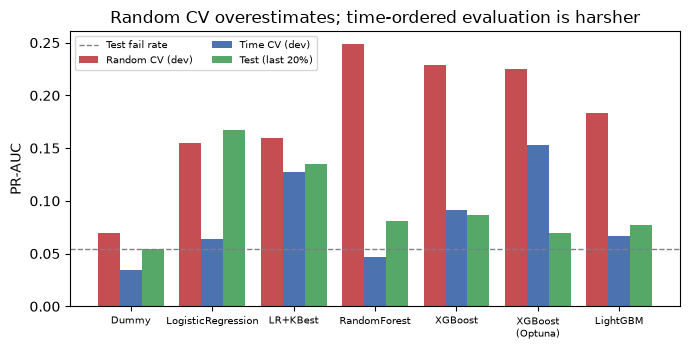

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.6))
order = table["model"]
xpos = np.arange(len(order))
w = 0.27
ax.bar(xpos - w, table["random_cv_ap"], w, label="Random CV (dev)", color="#C44E52")
ax.bar(xpos, table["time_cv_ap"], w, label="Time CV (dev)", color="#4C72B0")
ax.bar(xpos + w, table["test_ap"], w, label="Test (last 20%)", color="#55A868")
ax.axhline(y_test.mean(), color="gray", ls="--", lw=1, label="Test fail rate")
ax.set_xticks(xpos)
ax.set_xticklabels([m.split(" (")[0].replace("LR + SelectKBest", "LR+KBest").split("(k=")[0] + ("\n(Optuna)" if "Optuna" in m else "") for m in order],
                   rotation=0, fontsize=7)
ax.set_ylabel("PR-AUC")
ax.set_title("Random CV overestimates; time-ordered evaluation is harsher")
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
fig.savefig("results/05_cv_vs_test.png", dpi=150)
plt.show()

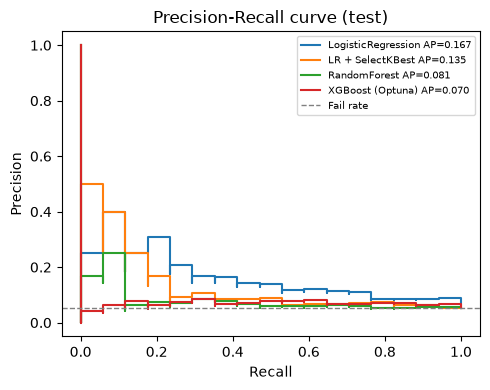

In [9]:
fig, ax = plt.subplots(figsize=(5, 4))
for name in ["LogisticRegression", f"LR + SelectKBest(k={best_k}, C={best_C})", "RandomForest", "XGBoost (Optuna)"]:
    p, r, _ = precision_recall_curve(y_test, test_proba[name])
    ax.step(r, p, where="post", label=f"{name.split('(k=')[0]} AP={average_precision_score(y_test, test_proba[name]):.3f}")
ax.axhline(y_test.mean(), color="gray", ls="--", lw=1, label="Fail rate")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-Recall curve (test)")
ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig("results/05_pr_curve_test.png", dpi=150)
plt.show()

In [10]:
result = {
    "env": ENV,
    "folds": [{"train": int(len(tr)), "valid": int(len(te)), "valid_fails": int(y_dev.iloc[te].sum())} for tr, te in FOLDS],
    "test_fail_rate": round(float(y_test.mean()), 4),
    "lr_grid_top": grid.head(6).round(4).to_dict(orient="records"),
    "lr_selected": {"k": str(best_k), "C": best_C},
    "optuna": {"trials": 40, "seconds": round(optuna_sec, 1), "best_time_cv_ap": round(study.best_value, 4),
               "best_params": study.best_params},
    "table": table.round(4).to_dict(orient="records"),
}
Path("results/05_models.json").write_text(json.dumps(result, ensure_ascii=False, indent=2), encoding="utf-8")
np.save("results/05_test_proba.npy", test_proba, allow_pickle=True)
print("saved")

saved
